# Proton CT: a single-sided scan of the abdomen

A proton therapy plan needs each tissue's relative stopping power (RSP): how much faster than water it slows protons. Plans
take it from an X-ray CT through a calibration curve, which leaves an uncertainty of 1 to 3% in the protons' range. Proton
CT measures it directly. A proton loses energy along its path, and from what is left a detector behind the patient gives
its water-equivalent path length (WEPL): the line integral of the RSP along the path, in mm. Reconstructing the RSP from
many protons' WEPLs is a tomography problem, with one complication: protons scatter, so their paths are curved and known
only approximately.

This tutorial reconstructs a simulated scan of an adult abdomen: pencil beams of 330 MeV protons, a digital tracking
calorimeter (DTC) behind the patient that measures where each proton leaves and its range, and nothing in front. Such a
**single-sided** scanner fits in a treatment room, but it knows a proton's entry only from the pencil beam's spot, to a
few millimetres. The scan was simulated with GATE (Geant4) from a patient CT, and converted outside PyTomography into its
proton CT list mode file: one row per proton, with its entry, its exit and its WEPL.

It needs an NVIDIA GPU with [CuPy](../install.md) installed, which compiles the CUDA kernels that follow the protons'
paths: about a minute in all on an RTX 5090.

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("PCT/GATE-Abdomen330-DTC")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("PCT/GATE-Abdomen330-DTC")

PCT/GATE-Abdomen330-DTC cannot be downloaded yet, so the files already in its folder are used as they are, unchecked.


In [2]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
import pytomography
from pytomography import io
from pytomography.projectors.PCT import PCTSystemMatrix, hull_from_image
from pytomography.algorithms import FilteredBackProjection, SART

In [3]:
# Memory: the scan (a quarter of the simulation's protons, 47 million) takes 1.9 GB of RAM, and the tutorial peaks at
# about 7 GB of RAM and 1 GB of GPU memory (measured on Windows); the filtered back projection prints its estimate
# before it runs (estimate_memory). Protons go to the GPU a view at a time, in calls of at most 1.5 GB, so RAM_GB
# changes nothing here. To use less RAM, read fewer protons: io.PCT.load_listmode(..., fraction=0.5) keeps half of
# each view's protons as it reads (noisier images). The record's full file (all 188.6 million protons) holds 7.5 GB
# of protons.
RAM_GB = 25
pytomography.set_memory_budget(RAM_GB)

## 1. The scan

`io.PCT.load_listmode` reads the file into PyTomography's standard form `(projections, object_meta, proj_meta)`: the
projections are the protons' WEPLs (mm), and `proj_meta` (a `PCTProjMeta`) holds the protons. Each of the 360 views is a
set of pencil beams along +y of its own frame, with the patient turned by the view's angle. A proton is described where
it crosses two planes across the beam, one before the patient (`front`) and one after it (`rear`): its x and z there,
and its direction as the slopes dx/dy and dz/dy.

The reconstruction grid can be anything; here it is the grid of the simulation's true RSP, so that the two can be compared
voxel by voxel: 370 × 314 × 57 voxels of 0.98 × 0.98 × 2.5 mm.

In [4]:
folder = DATA / 'PCT' / 'GATE-Abdomen330-DTC'
truth = io.load_image(folder / 'truth_rsp.nii.gz')  # the RSP the simulation used

t0 = time.time()
wepl, object_meta, proj_meta = io.PCT.load_listmode(folder / 'abdomen330_spot_likely_quarter.h5',
                                                    dr=truth.voxel_size, shape=truth.shape)
print(proj_meta)
print(f"read in {time.time() - t0:.0f} s; WEPL from {float(wepl.min()):.0f} to {float(wepl.max()):.0f} mm")

PCTProjMeta(47,151,406 protons, 360 views, beam 330000 keV, entry FWHM per proton, z_center 0 mm)
read in 1 s; WEPL from -23 to 387 mm


The exit comes from the DTC's two front layers. The entry does not: without a front tracker, the conversion estimated
it from the proton's pencil beam (its central ray, as the beam delivery log gives it) combined with its exit traced back
to the entry plane. The file stores that most likely entry, and `proj_meta.entry_fwhm` says how far the proton may
really have entered from it: about 7 mm FWHM for most protons, a little less than the spot's own 8.7 mm. The entry's
direction turns with that offset by `proj_meta.beam_divergence`, as it does in a real beam. Binning each view's protons
by where they leave gives a radiograph of WEPL:

entry FWHM: median 7.1 mm (5th to 95th percentile 1.6 to 7.8 mm)


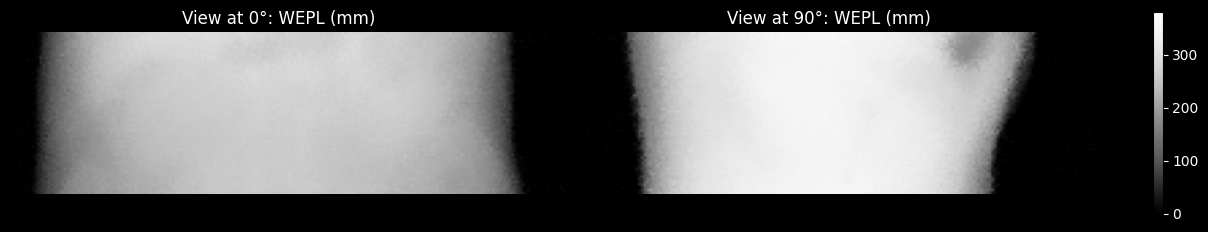

In [5]:
def wepl_radiograph(view, pixel=2.0):
    """The mean WEPL of a view's protons, binned by where they leave (x and z on the rear plane, mm)"""
    lo, hi = proj_meta.view_offsets[view], proj_meta.view_offsets[view + 1]
    x, z = proj_meta.exit[lo:hi, 0].numpy(), proj_meta.exit[lo:hi, 1].numpy()
    bins = [np.arange(-200, 200 + pixel, pixel), np.arange(-60, 60 + pixel, pixel)]
    total, _, _ = np.histogram2d(x, z, bins, weights=wepl[lo:hi].numpy())
    count, _, _ = np.histogram2d(x, z, bins)
    return np.where(count > 0, total / np.maximum(count, 1), np.nan)


fwhm = proj_meta.entry_fwhm.numpy()
print(f"entry FWHM: median {np.median(fwhm):.1f} mm (5th to 95th percentile {np.percentile(fwhm, 5):.1f} to "
      f"{np.percentile(fwhm, 95):.1f} mm)")
fig, axes = plt.subplots(1, 2, figsize=(12, 2.6), constrained_layout=True)
fig.patch.set_facecolor('black')
for ax, angle in zip(axes, [0, 90]):
    view = int(np.argmin(np.abs(proj_meta.angles.numpy() - angle)))
    im = ax.imshow(wepl_radiograph(view).T, cmap='Greys_r', origin='lower', extent=[-200, 200, -60, 60], vmin=0, vmax=380)
    ax.set_title(f'View at {angle}°: WEPL (mm)', color='white')
    ax.axis('off')
cb = fig.colorbar(im, ax=axes, shrink=0.8)
cb.ax.tick_params(colors='white')
plt.show()

## 2. Filtered back projection, in two passes

Filtered back projection (FBP) needs straight lines. `FilteredBackProjection` with a `PCTSystemMatrix` bins each proton's
WEPL into a parallel-beam sinogram along a straight line, filters it and back projects it. Two settings matter for a
single-sided scan:

- `band=5`: each proton is binned along a 5 × 5 grid of possible entries, weighted by `entry_fwhm`, rather than along its
  stored entry alone. Every proton of a spot otherwise starts from the same point, which leaves rings around the axis.
- Two passes. Outside the body a proton flies straight, so its path inside the body is closer to the chord between where
  its entry and exit lines meet the body's outline than to the line between its entry and exit points. The first pass
  bins by the points (`line='points'`, the default); its image gives the outline (`hull_from_image`: smoothed,
  thresholded at RSP 0.5, its largest piece), and the second pass bins by that chord (`line='hull'`).

In [6]:
system_matrix = PCTSystemMatrix(object_meta, proj_meta, path='straight', band=5)
fbp = FilteredBackProjection(wepl, system_matrix, filter='hann')
print(fbp.estimate_memory())  # its peak RAM and GPU memory, before it runs
t0 = time.time()
first_pass = fbp()
hull = hull_from_image(first_pass, object_meta)
system_matrix_hull = PCTSystemMatrix(object_meta, proj_meta, path='straight', band=5, hull=hull)
second_pass = FilteredBackProjection(wepl, system_matrix_hull, filter='hann', line='hull')()
print(f"two passes and the outline: {time.time() - t0:.1f} s")

Filtered back projection (PCTSystemMatrix)
Peak ~ 7.8 GB RAM, 1.9 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 1.9 GB RAM, 0.00 GB GPU (protons (entry and exit tables, entry spreads) and their WEPLs 1.9 RAM)
  one subset at a time: 0.00 GB RAM, 0.9 GB GPU (binning: sums and counts, one call's paths 0.9 GPU)
  Python, CUDA, allocator: 4.0 GB RAM, 1.0 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 0.4 GPU, memory the allocators keep (Windows) 1.0 RAM)
(plus whatever else your script keeps)


two passes and the outline: 4.5 s


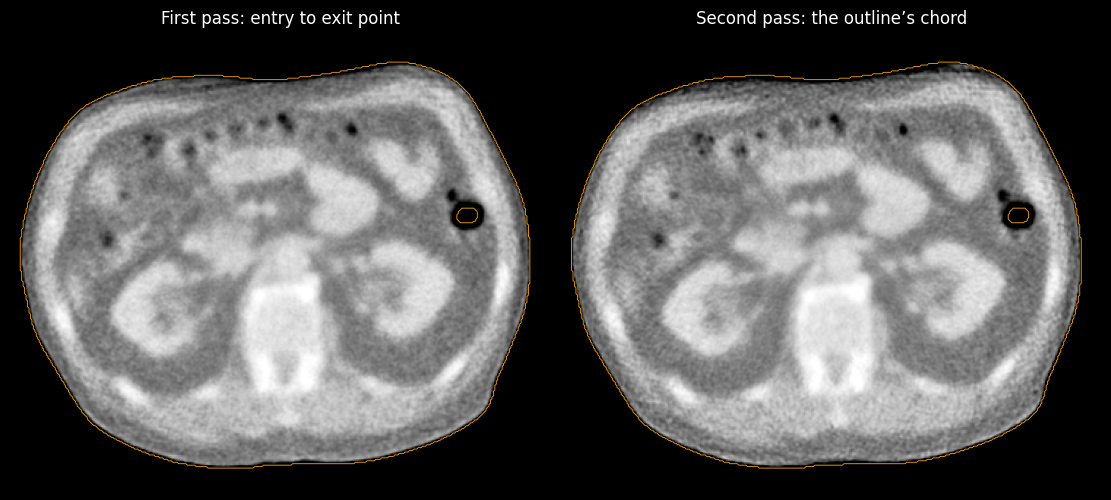

In [7]:
k = object_meta.shape[2] // 2  # the axial slice through the kidneys
fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
fig.patch.set_facecolor('black')
for ax, (image, name) in zip(axes, [(first_pass, 'First pass: entry to exit point'),
                                    (second_pass, 'Second pass: the outline’s chord')]):
    ax.imshow(image[:, :, k].T.cpu(), cmap='Greys_r', vmin=0.8, vmax=1.2)
    ax.contour(hull[:, :, k].T.numpy(), levels=[0.5], colors='orange', linewidths=0.6)
    ax.set_title(name, color='white')
    ax.axis('off')
plt.show()

## 3. SART along curved paths

Iterative reconstruction is not limited to straight lines. `PCTSystemMatrix` with `path='spline'` (the default) follows
each proton straight to the outline, along a cubic spline with its entry and exit directions inside it (Collins-Fekete et
al. 2015), and straight to its exit; a row of the system matrix is the exact length of that path in each voxel, so the
forward projection of an RSP image is each proton's WEPL. `SART` then corrects the image one subset of views at a time,
from the FBP image. Here it runs four passes through the data: three with a 3 × 3 band of entries and 180, 180 and 60
subsets (2, 2 and 6 views each), then one with the 5 × 5 band and 20 subsets, each step taking half of SART's correction
(`relaxation_sequence`). `support` holds the air outside the outline, grown by two voxels, at zero; without it, noise
leaves RSP in the air around the body, which adds to every WEPL computed from the image.

In [8]:
support = hull_from_image(first_pass, object_meta, grow=2)  # the outline grown by 2 voxels in each slice
image = second_pass.clamp(min=0)
t0 = time.time()
for band, n_subsets in [(3, 180), (3, 180), (3, 60), (5, 20)]:
    system_matrix = PCTSystemMatrix(object_meta, proj_meta, band=band, hull=hull)
    image = SART(system_matrix, wepl, object_initial=image, relaxation_sequence=lambda _: 0.5,
                 support=support)(n_iters=1, n_subsets=n_subsets)
sart = image
print(f"SART: {time.time() - t0:.0f} s")

SART: 29 s


## 4. Against the truth

The simulation knows the true RSP, and its record holds four organs on the same grid (`io.load_mask` reads the label
image). The beam covered the axial range from about −55 to +57 mm, so the slices beyond it have no data; the scores below
use the slices within ±50 mm. The spleen lies almost entirely above that slab, so it is left out.

In [9]:
true_rsp = truth.on(object_meta).to(pytomography.device)
z = (torch.arange(object_meta.shape[2]) - (object_meta.shape[2] - 1) / 2) * object_meta.dr[2]
scanned = (z.abs() <= 50).to(pytomography.device)[None, None, :]
labels = io.load_mask(folder / 'organs.nii.gz')
organs = {name: labels.on(object_meta, label=value, threshold=0.5).to(pytomography.device) & scanned
          for name, value in [('liver', 1), ('left kidney', 2), ('right kidney', 3)]}
print(f"{'':13s}{'true RSP':>9s}{'FBP':>9s}{'SART':>9s}   noise (SD of the error), FBP and SART")
for name, mask in organs.items():
    t = float(true_rsp[mask].mean())
    err = [100 * (float(r[mask].mean()) / t - 1) for r in (second_pass, sart)]
    sd = [float((r - true_rsp)[mask].std()) for r in (second_pass, sart)]
    print(f"{name:13s}{t:9.4f}{err[0]:+8.2f}%{err[1]:+8.2f}%   {sd[0]:.3f}  {sd[1]:.3f}")

              true RSP      FBP     SART   noise (SD of the error), FBP and SART
liver           1.1047   -0.82%   -0.32%   0.021  0.051
left kidney     1.1034   -1.38%   -0.50%   0.024  0.043
right kidney    1.1031   -1.56%   -0.58%   0.025  0.043


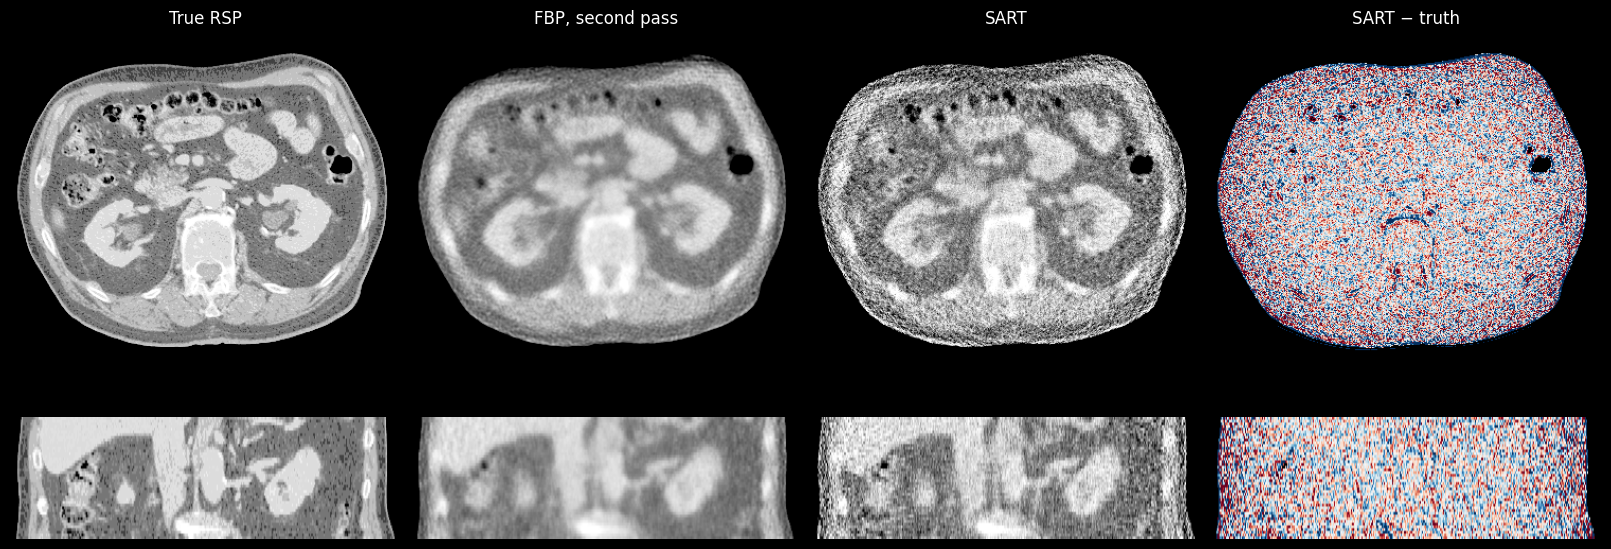

In [10]:
j = object_meta.shape[1] // 2  # the coronal slice through the middle of the body
in_beam = (z.abs() <= 55).nonzero().ravel()
rows = slice(int(in_beam[0]), int(in_beam[-1]) + 1)
coronal_height = (rows.stop - rows.start) * object_meta.dr[2] / object_meta.dr[0]
fig, axes = plt.subplots(2, 4, figsize=(16, 5.6), constrained_layout=True,
                         gridspec_kw={'height_ratios': [object_meta.shape[1], coronal_height]})
fig.patch.set_facecolor('black')
difference = torch.where(true_rsp > 0.5, sart - true_rsp, torch.nan)  # inside the body
images = [(true_rsp, 'True RSP'), (second_pass, 'FBP, second pass'), (sart, 'SART'), (difference, 'SART − truth')]
error_map = plt.get_cmap('RdBu_r').with_extremes(bad='black')
for col, (img, name) in enumerate(images):
    a = img.cpu()
    window = dict(cmap=error_map, vmin=-0.1, vmax=0.1) if col == 3 else dict(cmap='Greys_r', vmin=0.8, vmax=1.2)
    axes[0, col].imshow(a[:, :, k].T, **window)
    axes[1, col].imshow(a[:, j, rows].T, origin='lower', aspect=object_meta.dr[2] / object_meta.dr[0], **window)
    axes[0, col].set_title(name, color='white')
for ax in axes.flat:
    ax.axis('off')
plt.show()

FBP's image is smooth, blurred by its Hann window and by binning curved paths along straight lines, so organs next to
fat read low: by about 1.5% in the kidneys. SART, which fits each proton's WEPL along its own curved path, removes most
of that bias, and its image is sharper at the bone and the bowel gas; at this quarter of the protons it is also about
twice as noisy, voxel by voxel. Noise in single voxels is not what a plan uses, though.

## 5. Range errors

A treatment plan does not read the image voxel by voxel: it adds the RSP up along each beam, to place the Bragg peak. The
error that matters is therefore the error in those sums. The forward projection of an image along the scan's own proton
paths gives them directly: the difference between the reconstruction's and the truth's is the range error a beam along
that path would have, in mm of water. Here every 36th view (10 views, a million protons through the body):

In [11]:
system_matrix = PCTSystemMatrix(object_meta, proj_meta, band=1, hull=hull)
system_matrix.set_n_subsets(36)  # subset 0: views 0, 36, 72, ...
true_sums = system_matrix.forward(true_rsp, subset_idx=0)
through = true_sums > 20  # protons that crossed the body
for image, name in [(second_pass, 'FBP'), (sart, 'SART')]:
    error = (system_matrix.forward(image, subset_idx=0) - true_sums)[through]
    print(f"{name:5s} range error: mean {float(error.mean()):+.2f} mm, 95% within "
          f"{float(error.abs().quantile(0.95)):.2f} mm ({int(through.sum()):,} protons)")

FBP   range error: mean -0.19 mm, 95% within 3.35 mm (1,050,896 protons)
SART  range error: mean -0.06 mm, 95% within 2.78 mm (1,050,896 protons)


## Save the image

`io.save_nifti` writes the SART image with its grid (`object_meta`): RSP, with no units, in the scanner's frame (the
rotation axis at x = y = 0).

In [12]:
saved = io.save_nifti(sart, OUTPUT / 't_pct_abdomen' / 'sart_rsp.nii.gz', object_meta, units='RSP')

## Next steps

- The record also holds every proton the scan kept (188.6 million, 7.5 GB): read it with
  `io.PCT.load_listmode(folder / 'abdomen330_spot_likely.h5', ...)` for images with half the noise.
- The simulation itself (each proton's truth and every DTC cluster, the phantom and the patient CT) is its own record,
  [doi:10.5281/zenodo.23814741](https://doi.org/10.5281/zenodo.23814741), and the code that simulated the scan and
  converted it into the list mode file is at [pct-gate-simulation](https://github.com/lukepolson/pct-gate-simulation).
  Any scanner or simulation converted into the same file can be reconstructed as here (`io.PCT.save_listmode` writes
  one).
- With a front tracker the entry is measured: such a file has `entry_fwhm` 0, and `band=1` is enough.